# 6 Sept 2026

In [1]:
#!pip3 install imbalanced-learn

In [2]:
import pandas as pd
from imblearn.under_sampling import RandomUnderSampler

df = pd.read_csv(r"C:\Users\barat\OneDrive\Documents\GitHub\Data-Science\Data\fraudTest.csv",index_col=0)
X = df.drop('is_fraud', axis=1)
y = df['is_fraud']
sampler = RandomUnderSampler(random_state=42)
X_resampled, y_resampled = sampler.fit_resample(X, y)
df = pd.concat([X_resampled, y_resampled], axis=1)
df

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
547885,2020-12-29 19:17:03,371226440126102,"fraud_Medhurst, Cartwright and Ebert",personal_care,60.51,Stacy,Lambert,F,85430 Julie Trafficway Suite 792,Mulberry Grove,...,38.9311,-89.2463,1810,Race relations officer,1974-12-24,048c8b965dfcbdd9b023f6a5160beb0d,1388344623,39.205918,-88.295627,0
528140,2020-12-26 03:46:04,6596735789587928,fraud_Pouros-Haag,shopping_pos,2.36,Spencer,Williams,M,1145 Tony Drive Suite 080,Watertown,...,44.9595,-93.8482,5619,Licensed conveyancer,1959-01-15,828b54bd4d205f1114bce6fa8bc8f433,1388029564,44.826412,-93.239743,0
129300,2020-08-04 22:27:26,30551643947183,"fraud_Mante, Luettgen and Hackett",health_fitness,5.55,Morgan,Smith,F,1441 Bradley Place,Grover,...,35.1836,-81.4552,5621,Toxicologist,1973-11-14,383ac06cc8c02ef1e2c2bee329a30f77,1375655246,34.787130,-81.789226,0
354681,2020-11-05 11:29:52,6011388901471808,"fraud_Goldner, Kovacek and Abbott",grocery_pos,115.80,Jacqueline,Marsh,F,950 Sheryl Spurs,Dunlevy,...,40.1151,-79.8627,427,Mining engineer,1951-02-05,506ea157ec09c9f04eb3ea8bed59d33a,1383650992,39.342100,-80.375392,0
182576,2020-08-24 12:08:18,6011348830550197,"fraud_Turner, Ziemann and Lehner",food_dining,8.30,Samuel,Johnston,M,16285 Jessica Lights,Birmingham,...,33.4629,-86.7904,493806,Musician,1980-07-12,5646a4a1c03bf24f0dcc364e0116f7cd,1377346098,33.627330,-87.257660,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
517197,2020-12-22 22:05:48,2242176657877538,"fraud_Willms, Kris and Bergnaum",shopping_pos,1041.51,Travis,Daniel,M,1327 Rose Causeway Apt. 610,Senatobia,...,34.6323,-89.8855,14462,Database administrator,1959-03-03,35b0297dd026d2e9a75d024a5dec7955,1387749948,34.573471,-89.911011,1
517274,2020-12-22 22:18:07,2242176657877538,fraud_Kuhn LLC,shopping_pos,868.09,Travis,Daniel,M,1327 Rose Causeway Apt. 610,Senatobia,...,34.6323,-89.8855,14462,Database administrator,1959-03-03,da7f67d7375f10a054a3d919448c45dd,1387750687,34.091227,-90.390612,1
517341,2020-12-22 22:31:48,2242176657877538,"fraud_Mosciski, Ziemann and Farrell",shopping_net,1039.42,Travis,Daniel,M,1327 Rose Causeway Apt. 610,Senatobia,...,34.6323,-89.8855,14462,Database administrator,1959-03-03,25b076c7bcd70f272c1c5326bb234f4b,1387751508,34.628434,-90.284780,1
517529,2020-12-22 23:06:03,2242176657877538,fraud_Bauch-Raynor,grocery_pos,289.27,Travis,Daniel,M,1327 Rose Causeway Apt. 610,Senatobia,...,34.6323,-89.8855,14462,Database administrator,1959-03-03,2df7d894868fbc99ec1d8b055585fc9d,1387753563,34.746063,-90.401093,1


In [3]:
df.shape

(4290, 22)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4290 entries, 547885 to 517571
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   trans_date_trans_time  4290 non-null   object 
 1   cc_num                 4290 non-null   int64  
 2   merchant               4290 non-null   object 
 3   category               4290 non-null   object 
 4   amt                    4290 non-null   float64
 5   first                  4290 non-null   object 
 6   last                   4290 non-null   object 
 7   gender                 4290 non-null   object 
 8   street                 4290 non-null   object 
 9   city                   4290 non-null   object 
 10  state                  4290 non-null   object 
 11  zip                    4290 non-null   int64  
 12  lat                    4290 non-null   float64
 13  long                   4290 non-null   float64
 14  city_pop               4290 non-null   int64  
 15  jo

In [5]:
df.describe(include='object')

,trans_date_trans_time,merchant,category,first,last,gender,street,city,state,job,dob,trans_num
count,4290,4290,4290,4290,4290,4290,4290,4290,4290,4290,4290,4290
unique,4290,678,14,314,429,2,795,739,49,446,786,4290
top,2020-12-29 19:17:03,fraud_Kilback LLC,grocery_pos,Christopher,Williams,F,444 Robert Mews,Birmingham,NY,Science writer,1977-03-23,048c8b965dfcbdd9b023f6a5160beb0d
freq,1,23,687,127,118,2361,26,35,328,40,27,1


In [6]:
missing_values = df.isna().sum()
missing_percent = (df.isna().mean()*100).round(2)
pd.DataFrame({'Missing Values': missing_values,
              'Missing Percentage': missing_percent}).sort_values(by='Missing Values', ascending=False    )

,Missing Values,Missing Percentage
trans_date_trans_time,0,0.0
cc_num,0,0.0
merchant,0,0.0
category,0,0.0
amt,0,0.0
first,0,0.0
last,0,0.0
gender,0,0.0
street,0,0.0
city,0,0.0


In [7]:
df.duplicated().sum()
df = df.drop_duplicates()
df

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
547885,2020-12-29 19:17:03,371226440126102,"fraud_Medhurst, Cartwright and Ebert",personal_care,60.51,Stacy,Lambert,F,85430 Julie Trafficway Suite 792,Mulberry Grove,...,38.9311,-89.2463,1810,Race relations officer,1974-12-24,048c8b965dfcbdd9b023f6a5160beb0d,1388344623,39.205918,-88.295627,0
528140,2020-12-26 03:46:04,6596735789587928,fraud_Pouros-Haag,shopping_pos,2.36,Spencer,Williams,M,1145 Tony Drive Suite 080,Watertown,...,44.9595,-93.8482,5619,Licensed conveyancer,1959-01-15,828b54bd4d205f1114bce6fa8bc8f433,1388029564,44.826412,-93.239743,0
129300,2020-08-04 22:27:26,30551643947183,"fraud_Mante, Luettgen and Hackett",health_fitness,5.55,Morgan,Smith,F,1441 Bradley Place,Grover,...,35.1836,-81.4552,5621,Toxicologist,1973-11-14,383ac06cc8c02ef1e2c2bee329a30f77,1375655246,34.787130,-81.789226,0
354681,2020-11-05 11:29:52,6011388901471808,"fraud_Goldner, Kovacek and Abbott",grocery_pos,115.80,Jacqueline,Marsh,F,950 Sheryl Spurs,Dunlevy,...,40.1151,-79.8627,427,Mining engineer,1951-02-05,506ea157ec09c9f04eb3ea8bed59d33a,1383650992,39.342100,-80.375392,0
182576,2020-08-24 12:08:18,6011348830550197,"fraud_Turner, Ziemann and Lehner",food_dining,8.30,Samuel,Johnston,M,16285 Jessica Lights,Birmingham,...,33.4629,-86.7904,493806,Musician,1980-07-12,5646a4a1c03bf24f0dcc364e0116f7cd,1377346098,33.627330,-87.257660,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
517197,2020-12-22 22:05:48,2242176657877538,"fraud_Willms, Kris and Bergnaum",shopping_pos,1041.51,Travis,Daniel,M,1327 Rose Causeway Apt. 610,Senatobia,...,34.6323,-89.8855,14462,Database administrator,1959-03-03,35b0297dd026d2e9a75d024a5dec7955,1387749948,34.573471,-89.911011,1
517274,2020-12-22 22:18:07,2242176657877538,fraud_Kuhn LLC,shopping_pos,868.09,Travis,Daniel,M,1327 Rose Causeway Apt. 610,Senatobia,...,34.6323,-89.8855,14462,Database administrator,1959-03-03,da7f67d7375f10a054a3d919448c45dd,1387750687,34.091227,-90.390612,1
517341,2020-12-22 22:31:48,2242176657877538,"fraud_Mosciski, Ziemann and Farrell",shopping_net,1039.42,Travis,Daniel,M,1327 Rose Causeway Apt. 610,Senatobia,...,34.6323,-89.8855,14462,Database administrator,1959-03-03,25b076c7bcd70f272c1c5326bb234f4b,1387751508,34.628434,-90.284780,1
517529,2020-12-22 23:06:03,2242176657877538,fraud_Bauch-Raynor,grocery_pos,289.27,Travis,Daniel,M,1327 Rose Causeway Apt. 610,Senatobia,...,34.6323,-89.8855,14462,Database administrator,1959-03-03,2df7d894868fbc99ec1d8b055585fc9d,1387753563,34.746063,-90.401093,1


In [8]:
df['is_fraud'].value_counts(normalize=True)*100

is_fraud
0    50.0
1    50.0
Name: proportion, dtype: float64

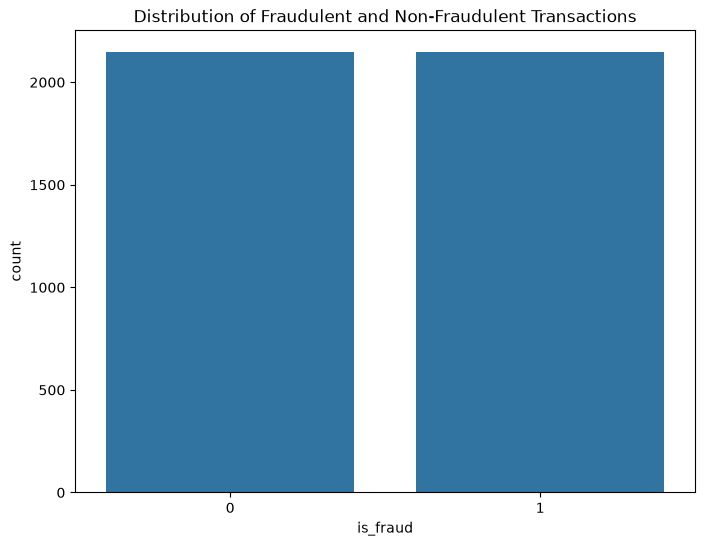

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.countplot(x='is_fraud', data=df)
plt.title('Distribution of Fraudulent and Non-Fraudulent Transactions')
plt.show()

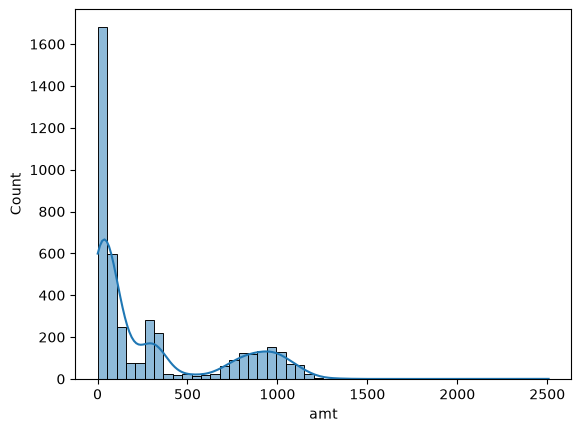

In [10]:
sns.histplot(df['amt'], kde=True)
plt.show()

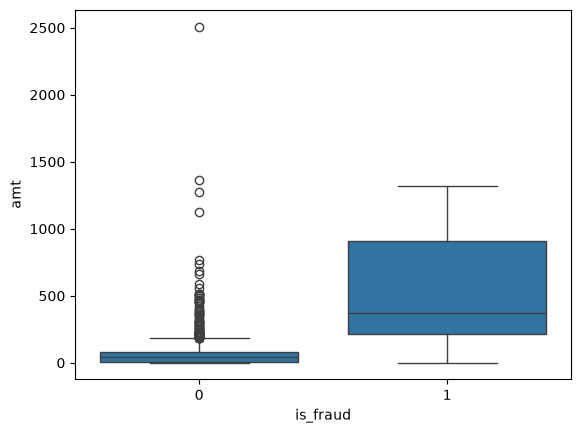

In [11]:
sns.boxplot(x='is_fraud', y='amt', data=df)
plt.show()

In [12]:
df.groupby('is_fraud')['amt'].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,2145.0,63.530098,101.347364,1.01,9.46,44.53,80.16,2507.65
1,2145.0,528.356494,392.747594,1.78,214.51,371.94,907.77,1320.92


In [13]:
fraud_by_category = df.groupby('category')['is_fraud'].agg(['count', 'sum', 'mean']).sort_values(by='mean', ascending=False)
fraud_by_category

,count,sum,mean
category,,,
shopping_net,655,506,0.772519
grocery_pos,687,485,0.705968
misc_net,385,267,0.693506
shopping_pos,415,213,0.513253
gas_transport,352,154,0.437500
travel,113,40,0.353982
misc_pos,208,72,0.346154
grocery_net,122,41,0.336066
personal_care,221,70,0.316742


In [14]:
pd.crosstab(df['gender'], df['is_fraud'], normalize='index') * 100

is_fraud,0,1
gender,,
F,50.698856,49.301144
M,49.144635,50.855365


In [15]:
df.columns

Index(['trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt',
       'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat',
       'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat',
       'merch_long', 'is_fraud'],
      dtype='object')

In [16]:
df.drop(['cc_num', 'first', 'last', 'street','trans_num','unix_time' ], axis=1, inplace=True)
df

,trans_date_trans_time,merchant,category,amt,gender,city,state,zip,lat,long,city_pop,job,dob,merch_lat,merch_long,is_fraud
547885,2020-12-29 19:17:03,"fraud_Medhurst, Cartwright and Ebert",personal_care,60.51,F,Mulberry Grove,IL,62262,38.9311,-89.2463,1810,Race relations officer,1974-12-24,39.205918,-88.295627,0
528140,2020-12-26 03:46:04,fraud_Pouros-Haag,shopping_pos,2.36,M,Watertown,MN,55388,44.9595,-93.8482,5619,Licensed conveyancer,1959-01-15,44.826412,-93.239743,0
129300,2020-08-04 22:27:26,"fraud_Mante, Luettgen and Hackett",health_fitness,5.55,F,Grover,NC,28073,35.1836,-81.4552,5621,Toxicologist,1973-11-14,34.787130,-81.789226,0
354681,2020-11-05 11:29:52,"fraud_Goldner, Kovacek and Abbott",grocery_pos,115.80,F,Dunlevy,PA,15432,40.1151,-79.8627,427,Mining engineer,1951-02-05,39.342100,-80.375392,0
182576,2020-08-24 12:08:18,"fraud_Turner, Ziemann and Lehner",food_dining,8.30,M,Birmingham,AL,35229,33.4629,-86.7904,493806,Musician,1980-07-12,33.627330,-87.257660,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
517197,2020-12-22 22:05:48,"fraud_Willms, Kris and Bergnaum",shopping_pos,1041.51,M,Senatobia,MS,38668,34.6323,-89.8855,14462,Database administrator,1959-03-03,34.573471,-89.911011,1
517274,2020-12-22 22:18:07,fraud_Kuhn LLC,shopping_pos,868.09,M,Senatobia,MS,38668,34.6323,-89.8855,14462,Database administrator,1959-03-03,34.091227,-90.390612,1
517341,2020-12-22 22:31:48,"fraud_Mosciski, Ziemann and Farrell",shopping_net,1039.42,M,Senatobia,MS,38668,34.6323,-89.8855,14462,Database administrator,1959-03-03,34.628434,-90.284780,1
517529,2020-12-22 23:06:03,fraud_Bauch-Raynor,grocery_pos,289.27,M,Senatobia,MS,38668,34.6323,-89.8855,14462,Database administrator,1959-03-03,34.746063,-90.401093,1


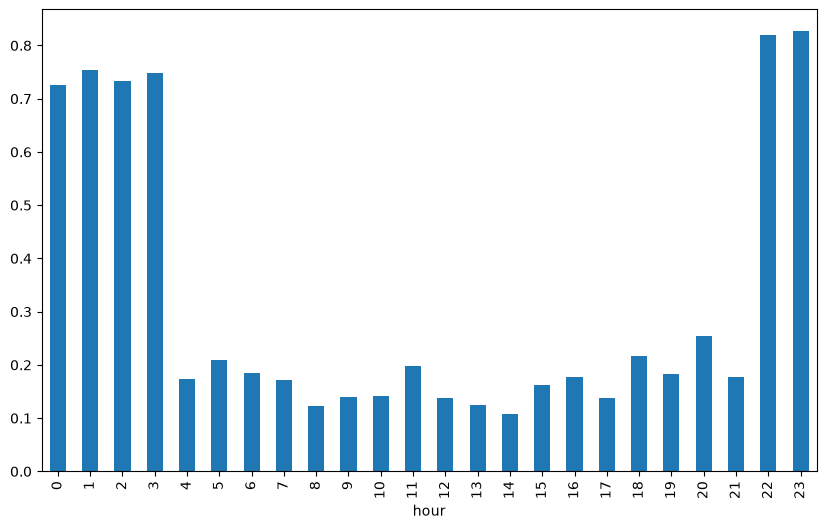

In [17]:
df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])
df['month'] = df['trans_date_trans_time'].dt.month
df['day'] = df['trans_date_trans_time'].dt.day
df['day_of_week'] = df['trans_date_trans_time'].dt.dayofweek
df['hour'] = df['trans_date_trans_time'].dt.hour
df['weekend'] = df['day_of_week'].apply(lambda x: 1 if x >= 5 else 0)
hour_fraud = df.groupby('hour')['is_fraud'].mean()
hour_fraud.plot(kind='bar', figsize=(10, 6))
plt.show()

In [18]:
df['age'] = 2026 - pd.to_datetime(df['dob']).dt.year
df.drop(['dob','trans_date_trans_time','city','zip','lat','long','merch_lat','merch_long'], axis=1, inplace=True)
df


,merchant,category,amt,gender,state,city_pop,job,is_fraud,month,day,day_of_week,hour,weekend,age
547885,"fraud_Medhurst, Cartwright and Ebert",personal_care,60.51,F,IL,1810,Race relations officer,0,12,29,1,19,0,52
528140,fraud_Pouros-Haag,shopping_pos,2.36,M,MN,5619,Licensed conveyancer,0,12,26,5,3,1,67
129300,"fraud_Mante, Luettgen and Hackett",health_fitness,5.55,F,NC,5621,Toxicologist,0,8,4,1,22,0,53
354681,"fraud_Goldner, Kovacek and Abbott",grocery_pos,115.80,F,PA,427,Mining engineer,0,11,5,3,11,0,75
182576,"fraud_Turner, Ziemann and Lehner",food_dining,8.30,M,AL,493806,Musician,0,8,24,0,12,0,46
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
517197,"fraud_Willms, Kris and Bergnaum",shopping_pos,1041.51,M,MS,14462,Database administrator,1,12,22,1,22,0,67
517274,fraud_Kuhn LLC,shopping_pos,868.09,M,MS,14462,Database administrator,1,12,22,1,22,0,67
517341,"fraud_Mosciski, Ziemann and Farrell",shopping_net,1039.42,M,MS,14462,Database administrator,1,12,22,1,22,0,67
517529,fraud_Bauch-Raynor,grocery_pos,289.27,M,MS,14462,Database administrator,1,12,22,1,23,0,67


In [19]:
df = pd.get_dummies(df, columns=['merchant','category', 'gender','state','job'], drop_first=True,dtype=int)

X = df.drop('is_fraud', axis=1)
y = df['is_fraud']


In [20]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import classification_report, confusion_matrix
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
models = [LogisticRegression(max_iter=1000),KNeighborsClassifier(n_neighbors=5),DecisionTreeClassifier()]
for model in models:
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    print("Training Classification Report:\n", classification_report(y_train, train_pred))
    print("Testing Classification Report:\n", classification_report(y_test, test_pred))
    print("Training Confusion Matrix:\n", confusion_matrix(y_train, train_pred))
    print("Testing Confusion Matrix:\n", confusion_matrix(y_test, test_pred))


c:\Users\barat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.87      0.84      1716
           1       0.86      0.79      0.82      1716

    accuracy                           0.83      3432
   macro avg       0.83      0.83      0.83      3432
weighted avg       0.83      0.83      0.83      3432

Testing Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.88      0.83       429
           1       0.87      0.77      0.81       429

    accuracy                           0.83       858
   macro avg       0.83      0.83      0.82       858
weighted avg       0.83      0.83      0.82       858

Training Confusion Matrix:
 [[1501  215]
 [ 368 1348]]
Testing Confusion Matrix:
 [[378  51]
 [ 99 330]]
Training Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.91      0.90      1716
           1       0.91      0.90 

In [21]:
layers = [2,3,4,5]
epochs = [50,100,150]


(2,50),(2,100),(2,150),
(3,50),(3,100),(3,150),
(4,50),(4,100),(4,150),
(5,50),(5,100),(5,150)

((5, 50), (5, 100), (5, 150))

In [22]:
from transformers import pipeline
import torch

chatbot = pipeline(
    "text-generation",
    model="distilgpt2"
)
prompt = "What is artificial intelligence?"

result = chatbot(
    prompt,
    max_new_tokens=80,
    do_sample=True
)

print(result[0]["generated_text"])
def chat(message):
    response = chatbot(
        message,
        max_new_tokens=80,
        do_sample=True
    )

    return response[0]["generated_text"]
import gradio as gr

interface = gr.Interface(
    fn=chat,
    inputs=gr.Textbox(
        label="Ask your question"
    ),
    outputs=gr.Textbox(
        label="Chatbot Response"
    ),
    title="EdVanta AI Chatbot"
)

interface.launch()

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

What is artificial intelligence? Not exactly. The answer is that it is, at least as the American way of thinking about artificial intelligence, that is a pretty good idea. It's hard to know.




But the answer is that artificial intelligence is not that good. We know that AI is very good at creating, making, and manipulating, some things. But the question is, is it really good at
* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [23]:
!pip3 install huggingface_hub transformers tokenizers


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\barat\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [24]:
!pip3 install pytorch torchvision torchaudio

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 19.7 MB/s  0:00:00
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   -- ------------------------------------- 7.1/126.7 MB 33.6 MB/s eta 0:00:04
   ---- ----------------------------------- 13.6/126.7 MB 32.0 MB/s eta 0:00:04
   ------ --------------------------------- 20.2/126.7 MB 31.5 MB/s eta 0:00:04
   -------- ------------

  error: subprocess-exited-with-error
  
  × Building wheel for pytorch (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [37 lines of output]
      Traceback (most recent call last):
        File "C:\Users\barat\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 389, in <module>
          main()
          ~~~~^^
        File "C:\Users\barat\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 373, in main
          json_out["return_val"] = hook(**hook_input["kwargs"])
                                   ~~~~^^^^^^^^^^^^^^^^^^^^^^^^
        File "C:\Users\barat\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 280, in build_wheel
          return _build_backend().build_wheel(
                 ~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
              wheel_directory, config_settings,

In [25]:
from transformers import pipeline
import torch
chabot = pipeline(
    "text-generation",
    model="distilgpt2"
)
prompt = "What is artificial intelligence?"
result = chabot(
    prompt,
    max_new_tokens=80,
    do_sample=True
)
print(result[0]["generated_text"])

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

What is artificial intelligence? That is exactly what it is.




In a study of over 1,000 students, the researchers found that robots and robots with a greater degree of intelligence use their brains to perform tasks like math and math. This is one of the first findings in a major paper in the field of artificial intelligence. It was the first time a machine has ever been able to perform a task like
